# M04 — Induced prism forward physics and controls

**Question:** How closely does the induced-prism operator agree with an independent physical oracle, and when does linear TMI diverge from exact magnitude?

**Level 3 · Prerequisites: foundations notebook; read time: 25 minutes.**



## Objectives

Run the product induced-prism forward operator on an explicit one-cell synthetic request. Compare components with Choclo’s independent physical prism function and distinguish linear TMI from exact magnitude anomaly. This is not susceptibility inversion or remanence classification.


## Setup

Use the already reviewed Python 3.12 pipeline environment. This notebook installs nothing.
Import repository code and confirm its source file.

In [1]:
import sys
from pathlib import Path
import numpy as np

root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
import magnetic_forward

# Reuse the product's frozen synthetic physical control.
import choclo
from choclo.constants import VACUUM_MAGNETIC_PERMEABILITY as mu0

# Fixed one-prism simulation input; the source is modeled, not observed.
request = {
    "schema": "magnetic-prism-forward-request-1",
    "engine": magnetic_forward.ENGINE,
    "frame": dict(magnetic_forward.FRAME),
    "mesh": {
        "origin_m": np.array([-50.0, -40.0, -120.0]),
        "hx_m": np.array([100.0]),
        "hy_m": np.array([80.0]),
        "hz_m": np.array([120.0]),
        "active": np.array([True]),
    },
    "receivers_m": np.array([[0.0, 0.0, 100.0], [170.0, 30.0, 120.0], [-100.0, 160.0, 240.0]]),
    "susceptibility_si": np.array([0.03]),
    "inducing_field": {"amplitude_nt": 50000.0, "inclination_deg": 60.0, "declination_deg": 12.0},
}
prism_bounds = (-50.0, 50.0, -40.0, 40.0, -120.0, 0.0)
print(magnetic_forward.ENGINE)


simpeg-0.25.2-geoana-0.8.1-f64-induced-ram


## Data

Run the product induced-prism forward operator on an explicit one-cell synthetic request. Compare components with Choclo’s independent physical prism function and distinguish linear TMI from exact magnitude anomaly. This is not susceptibility inversion or remanence classification.

**Files:** `data-pipeline/magnetic_forward.py`, `docs/design/features/m04-induced-prism/algorithms.md`, `docs/design/features/m04-induced-prism/validation.md`.


## Method

For I positive down and D clockwise from north, f=(cos I sin D, cos I cos D, −sin I) in ENU; B₀=Ff. Uniform induced magnetization is M=χ·10⁻⁹B₀/μ₀ A m⁻¹. Secondary b gives linear TMI f·b; exact magnitude anomaly is |B₀+b|−F. Assumptions: uniform field, scalar susceptibility, no self-demagnetization and no remanence.

For inclination I and declination D, f=(cos I sin D, cos I cos D, −sin I) in east/north/up; Ff is the inducing field in nT. Scalar susceptibility χ is dimensionless and the ideal induced magnetization is M=χ·10⁻⁹Ff/μ₀ A m⁻¹. The secondary vector field integrates μ₀/(4π)[3(M·R)R/|R|⁵−M/|R|³] over each prism volume, then converts tesla to nT. Linear TMI is f·b. Exact magnitude anomaly is |Ff+b|−F, not |b|. Only linear TMI has the returned Jacobian with respect to χ. For |b|≪F, exact and linear anomalies approach one another; their difference is a diagnostic of approximation error.

Assumptions are uniform source field, scalar cellwise χ, no remanence, and no self-demagnetization. The processor does not infer those assumptions or classify a real survey. The added easting transect is a deterministic model experiment based on the product’s one-prism fixture. Its components are compared with an independent physical Choclo integral; the plotted exact-minus-linear curve shows the projection approximation for this case. A small forward-oracle difference validates only that controlled calculation, not inversion, field source validity or host acceptance.

Execute the product method on the declared control.

In [2]:
# Compare production components with Choclo's independent physical magnetic-prism function.
result = magnetic_forward.forward_magnetic(request)
f = result["inducing_field"]["direction_enu"]
F = request["inducing_field"]["amplitude_nt"]
M = request["susceptibility_si"][0] * F * 1e-9 * f / mu0
oracle = np.array([choclo.prism.magnetic_field(*r, *prism_bounds, *M) for r in request["receivers_m"]]) * 1e9
max_error = float(np.max(np.abs(result["field_components_nt"] - oracle)))
print(
    {
        "components_nT": result["field_components_nt"].tolist(),
        "linear_TMI_nT": result["linear_tmi_nt"].tolist(),
        "exact_magnitude_nT": result["exact_magnitude_anomaly_nt"].tolist(),
        "max_component_error_nT": max_error,
        "accepted": result["linearization"]["full_method_accepted"],
    }
)


{'components_nT': [[-3.083885319869999, -15.196751023702873, -52.600520412756026], [-8.37992389035097, -5.113501807685271, -1.3490249144903828], [0.9113899363806939, -3.1976523174842035, -1.2633513449759988]], 'linear_TMI_nT': [37.800466247765534, -2.203731988464365, -0.3750493011759808], 'exact_magnitude_nT': [37.81623823240539, -2.2027986027475563, -0.3749241901716595], 'max_component_error_nT': 1.8385293287792592e-13, 'accepted': False}


Adversarial or negative control: isolate one assumption or violate one declared physical constraint.

In [3]:
from copy import deepcopy

changed = deepcopy(request)
changed["inducing_field"]["declination_deg"] = 42.0
# Change only a declared field assumption; this is not field classification.
alternative = magnetic_forward.forward_magnetic(changed)
delta = float(np.max(np.abs(alternative["field_components_nt"] - result["field_components_nt"])))
print({"max_component_change_nT": delta})
assert delta > 0


{'max_component_change_nT': 6.84110757451481}


## State of the art

SimPEG/Geoana is the production framework ([Cockett et al., 2015](https://doi.org/10.1016/j.cageo.2015.09.015)); the product control compares it with an independent prism calculation. A changed field tests sensitivity but cannot identify the real field. Exact magnitude and linear TMI differ; the returned Jacobian applies to linear TMI only.
This deterministic synthetic transect uses the production operator and a separate physical oracle. The exact-minus-linear panel is an approximation diagnostic in nT, not a universal threshold or a measured anomaly.


In [4]:
from copy import deepcopy
import matplotlib.pyplot as plt

# Recompute a physical easting transect with the product method and independent Choclo oracle.
transect = deepcopy(request)
east = np.linspace(-500.0, 500.0, 81)
transect["receivers_m"] = np.column_stack([east, np.zeros_like(east), np.full_like(east, 100.0)])
p = magnetic_forward.forward_magnetic(transect)
oracle_components = (
    np.array([choclo.prism.magnetic_field(*r, *prism_bounds, *M) for r in transect["receivers_m"]]) * 1e9
)
err = float(np.max(np.abs(p["field_components_nt"] - oracle_components)))
linear = p["linear_tmi_nt"]
exact = p["exact_magnitude_anomaly_nt"]


### Compare the exact and linearized anomaly

The transect and component-wise Choclo comparison are computed first. This second step plots the full-vector magnitude anomaly against the first-order total-field projection and shows their difference as the secondary field grows relative to the background.

{'max_component_error_vs_oracle_nT': 2.4724666758402236e-13, 'max_exact_linear_difference_nT': 0.01622152471291116, 'max_secondary_to_background_ratio': 0.001096770958411151, 'full_method_accepted': False}


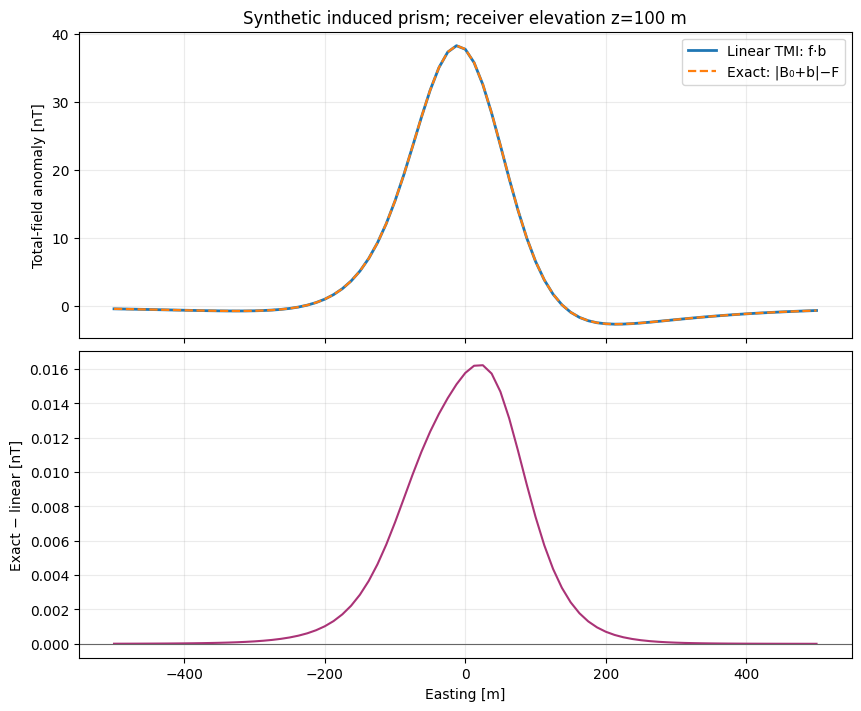

In [5]:
# Compare the exact and linearized anomaly.
fig, (ax, bx) = plt.subplots(2, 1, figsize=(8.5, 7), sharex=True, constrained_layout=True)
ax.plot(east, linear, label="Linear TMI: f·b", lw=2)
ax.plot(east, exact, "--", label="Exact: |B₀+b|−F", lw=1.6)
ax.set(ylabel="Total-field anomaly [nT]", title="Synthetic induced prism; receiver elevation z=100 m")
ax.legend()
ax.grid(alpha=0.25)
bx.plot(east, exact - linear, color="#aa3377")
bx.axhline(0, color=".4", lw=0.8)
bx.set(xlabel="Easting [m]", ylabel="Exact − linear [nT]")
bx.grid(alpha=0.25)
print(
    {
        "max_component_error_vs_oracle_nT": err,
        "max_exact_linear_difference_nT": p["linearization"]["maximum_abs_difference_nt"],
        "max_secondary_to_background_ratio": float(np.max(p["linearization"]["secondary_to_background_ratio"])),
        "full_method_accepted": p["linearization"]["full_method_accepted"],
    }
)
plt.show()


### Inspect the reference prism response

The plotted components show the signed ENU field generated by the declared induced prism at its receiver locations. Component polarity depends on the repository’s ENU convention and the inducing-field direction. This is a forward response for one ideal body; it does not estimate susceptibility, remanence, or whether a comparable source exists in the ground.


In [6]:
# Doubling susceptibility isolates forward amplitude response.
changed_chi = deepcopy(request)
changed_chi["susceptibility_si"] = request["susceptibility_si"] * 2
chi_result = magnetic_forward.forward_magnetic(changed_chi)
print(float(np.max(np.abs(chi_result["field_components_nt"] - result["field_components_nt"]))))


52.600520412756026


Changing inclination alone tests the declared vertical-field convention.

In [7]:
# Changing inclination alone tests the declared vertical-field convention.
changed_inc = deepcopy(request)
changed_inc["inducing_field"]["inclination_deg"] = 45.0
inc_result = magnetic_forward.forward_magnetic(changed_inc)
print(float(np.max(np.abs(inc_result["field_components_nt"] - result["field_components_nt"]))))


9.652375340721662


The prior transect compares the linear and exact observables at one declared susceptibility. This second calculation changes susceptibility over a threefold range while holding prism geometry, field and receivers fixed. It tests amplitude scaling and the size of the nonlinear magnitude correction against the same forward physics, which helps distinguish a stable shape change from a purely scalar amplitude change.

Recompute the easting transect at three susceptibility scales.

{0.5: 0.004056702754485997, 1.0: 0.01622152471291116, 2.0: 0.06484383398431248}


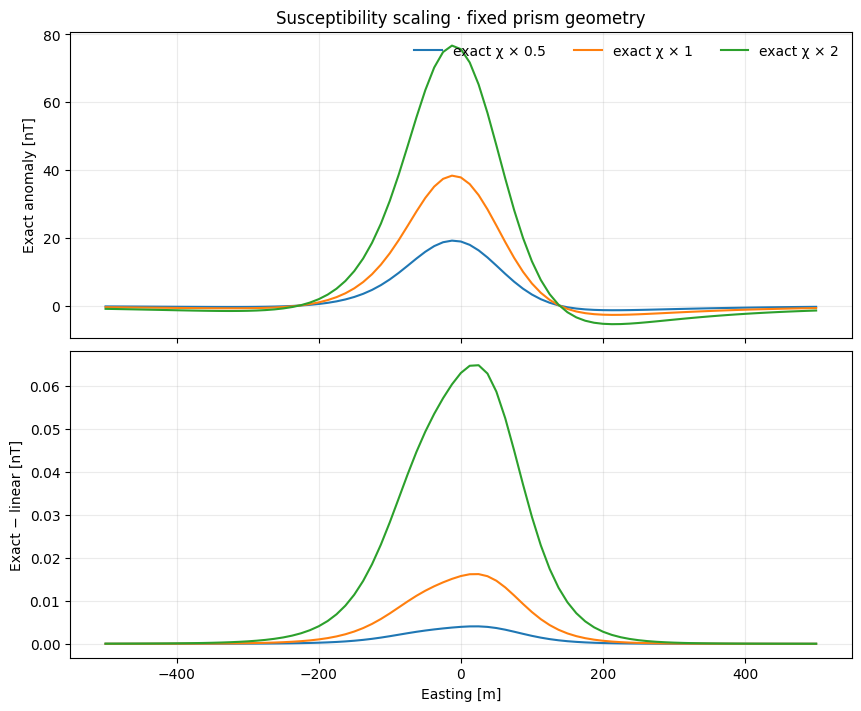

In [8]:
# Re-run the production forward method while changing susceptibility only.
import matplotlib.pyplot as plt

scales = (0.5, 1.0, 2.0)
profiles = {}
for scale in scales:
    case = deepcopy(transect)
    case["susceptibility_si"] = request["susceptibility_si"] * scale
    profiles[scale] = magnetic_forward.forward_magnetic(case)
fig, (ax, bx) = plt.subplots(2, 1, figsize=(8.5, 7), sharex=True, constrained_layout=True)
for scale, case_result in profiles.items():
    ax.plot(east, case_result["exact_magnitude_anomaly_nt"], label=f"exact χ × {scale:g}")
    bx.plot(east, case_result["exact_magnitude_anomaly_nt"] - case_result["linear_tmi_nt"], label=f"χ × {scale:g}")
ax.set(ylabel="Exact anomaly [nT]", title="Susceptibility scaling · fixed prism geometry")
bx.set(xlabel="Easting [m]", ylabel="Exact − linear [nT]")
ax.legend(frameon=False, ncol=3)
for panel in (ax, bx):
    panel.grid(alpha=0.25)
print(
    {
        scale: float(np.max(np.abs(v["exact_magnitude_anomaly_nt"] - v["linear_tmi_nt"])))
        for scale, v in profiles.items()
    }
)
plt.show()


The top panel shows the nonlinear exact magnitude anomaly as susceptibility changes; the lower panel isolates its departure from the linear projection. Because geometry, inducing field and receiver positions are held fixed, any differences arise from the changed induced moment and the exact vector norm. The linear response should scale proportionally with susceptibility, while the nonlinear correction grows as the secondary field becomes less negligible relative to the background field. This controlled sensitivity plot does not infer a field susceptibility distribution.

## Results

Use frozen independent tolerances, not rounded display values. A changed declination should change components. The operator sets field-source and full-method acceptance false; M04 survey inversion remains outside this lesson.


For an induced prism, the field direction, scalar susceptibility, prism bounds and receiver coordinates jointly define the forward response. The product operator computes secondary vector components and projects them along the inducing direction for first-order total magnetic intensity. The exact magnitude change retains the nonlinear norm. Choclo’s prism function gives an independent implementation of the physical integral on identical inputs; component-wise discrepancy is the meaningful numerical check. Varying declination alone tests orientation sensitivity. Neither oracle agreement nor a visually smooth anomaly establishes that the idealized scalar induced source is present in nature. Remanence, self-demagnetization, variable susceptibility, topography and field uncertainty
are outside this operator’s declared scope.

**Answer:** The maximum component discrepancy against Choclo is 2.47×10⁻¹³ nT. The exact-minus-linear TMI difference peaks at 0.0162215 nT while the secondary-to-background ratio is 0.00109677; the full method acceptance flag remains false.

The M04 operator computes secondary ENU field, linear TMI and exact magnitude from one induced prism; Choclo checks its components independently. This agreement validates one forward kernel, not susceptibility recovery, remanence or field geology.


### Susceptibility inversion and an induced-field failure control

Run the product 3D integral inversions on the seeded dipping-dyke survey with the declared inducing field. The reduced-coverage condition fits alternating stations and evaluates the interleaved observations; this deliberately favourable interpolation check is not a spatially independent field test. Then run the remanent-body construction, whose magnetization direction differs from the assumed uniform inducing field. Its scalar susceptibility fit is a **negative physical-model control**, while the vector solution estimates effective magnetization. These are independent solver executions, not plots of the precomputed browser cases.


In [9]:
# Run induced-dyke inversion and the remanent-direction negative control.
from geology import registry
import potential

magnetic_case = next(case for case in registry() if case["id"] == "MAGNETIC_DYKE")
magnetic_inverse = potential.solve_case(magnetic_case, "coverage", {})
magnetic_shape = tuple(magnetic_inverse["grid"]["shape"])
magnetic_methods = magnetic_inverse["methods"]
for method_id, method in magnetic_methods.items():
    metrics = method["metrics"]
    print(method["name"], {
        "fit_wrms": metrics["wrms"],
        "interleaved_holdout_wrms": metrics.get("heldout_wrms"),
        "model_rmse_si": metrics["model_rmse"],
        "initial_model_ratio": metrics["baseline_ratio"],
        "evaluation": method["evaluation"],
    })

remanence_case = next(case for case in registry() if case["id"] == "MAGNETIC_REMANENCE")
remanence_inverse = potential.solve_case(remanence_case, "coverage", {})
for method_id, method in remanence_inverse["methods"].items():
    metrics = method["metrics"]
    print("remanence control ·", method["name"], {
        "fit_wrms": metrics["wrms"],
        "interleaved_holdout_wrms": metrics.get("heldout_wrms"),
        "evaluation": method["evaluation"],
        "direction_error_deg": metrics.get("direction_error_deg"),
    })


Spatially regularized L2 {'fit_wrms': 1.0000000000000395, 'interleaved_holdout_wrms': 1.691955641240732, 'model_rmse_si': 0.010169835811351842, 'initial_model_ratio': 0.8677332890516457, 'evaluation': {'status': 'unresolved', 'reason_codes': ['low-model-correlation']}}
Spatial L1/L2 IRLS {'fit_wrms': 0.9999999999999093, 'interleaved_holdout_wrms': 1.6686725183695816, 'model_rmse_si': 0.010182723198108689, 'initial_model_ratio': 0.8688328952503335, 'evaluation': {'status': 'unresolved', 'reason_codes': ['low-model-correlation']}}
Vector magnetization {'fit_wrms': 0.9999999999998508, 'interleaved_holdout_wrms': 2.206407552591117, 'model_rmse_si': 0.010663700344632817, 'initial_model_ratio': 0.9098718942129508, 'evaluation': {'status': 'unresolved', 'reason_codes': ['withheld-data-not-predicted', 'low-model-correlation']}}
remanence control · Spatially regularized L2 {'fit_wrms': 0.9999999999999987, 'interleaved_holdout_wrms': 1.614411844560472, 'evaluation': {'status': 'negative-control'

Read predicted-data WRMS, model RMSE, improvement against the zero model, and the method verdict separately. Near-unit training WRMS does not guarantee withheld prediction. Scalar susceptibility and vector magnetization have different parameterizations; the vector norm is not a depth-resolved susceptibility estimate. In the remanent control, a good fit from a flexible vector model does not validate the induced-only scalar assumption.


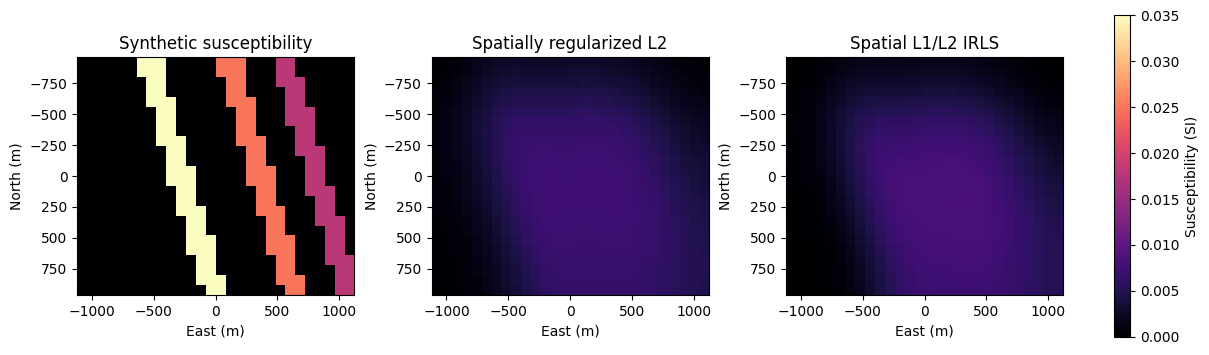

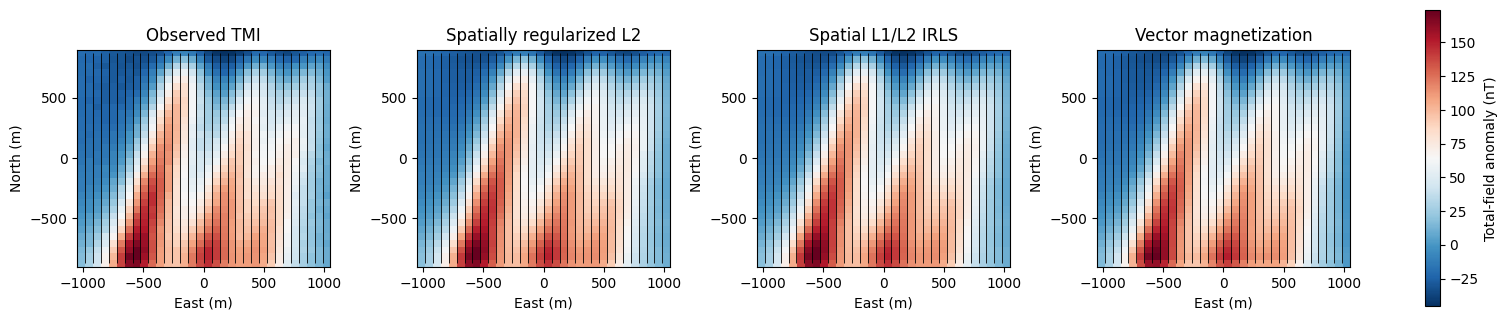

In [10]:
# Compare susceptibility sections and observed / predicted TMI maps.
truth = np.asarray(magnetic_inverse["truth"]).reshape(magnetic_shape)
z_index = magnetic_shape[0] // 2
models = [("Synthetic susceptibility", truth)] + [(magnetic_methods[key]["name"], np.asarray(magnetic_methods[key]["model"]).reshape(magnetic_shape)) for key in ("l2", "irls")]
limit = max(float(np.max(np.abs(volume[z_index]))) for _, volume in models)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, (title, volume) in zip(axes, models):
    image = ax.imshow(volume[z_index], origin="upper", cmap="magma", vmin=0, vmax=limit, extent=(-1120, 1120, 960, -960), aspect="equal")
    ax.set(title=title, xlabel="East (m)", ylabel="North (m)")
fig.colorbar(image, ax=axes, label="Susceptibility (SI)", shrink=.82)
plt.show()

survey = magnetic_inverse["survey"]
shape = tuple(survey["shape"])
active = np.asarray(survey["active"], dtype=bool).reshape(shape)
observed = np.asarray(survey["observed"]).reshape(shape)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), constrained_layout=True)
fields = [("Observed TMI", observed)] + [(magnetic_methods[key]["name"], np.asarray(magnetic_methods[key]["predicted"]).reshape(shape)) for key in ("l2", "irls", "vector")]
for ax, (title, field) in zip(axes, fields):
    image = ax.imshow(field, origin="lower", cmap="RdBu_r", extent=(-1050, 1050, -900, 900), aspect="equal")
    ax.contour(active, levels=[.5], colors="black", linewidths=.6, origin="lower", extent=(-1050, 1050, -900, 900))
    ax.set(title=title, xlabel="East (m)", ylabel="North (m)")
fig.colorbar(image, ax=axes, label="Total-field anomaly (nT)", shrink=.82)
plt.show()


**Interpretation and limits.** All prediction maps use the same station geometry and contour the fitted versus interleaved rows. The model figure uses one depth slice and a shared physical susceptibility scale across truth, L2 and IRLS. The remanent control uses a deliberately different magnetization direction; it is a misspecification test, not an attempt to tune the inducing-field direction. Both experiments are synthetic and use the same SimPEG/Geoana forward family for data generation and inversion. An independent inverse oracle, real survey custody, blocked external validation and field-geology truth remain outside this experiment.


## Summary

The independent implementation agrees to numerical precision for this one-cell synthetic geometry. The small linearization difference is consistent with the weak secondary field, but the false acceptance flag and idealized induced-only source preclude claims about field fit or recovered geology.





## References

- https://doi.org/10.1016/j.cageo.2015.09.015